# Laboratorio evaluativo del curso de Ética para la IA - Curso de Maestría
## Ética, sesgos, explicabilidad y documentación de inteligencia artificial

**Calificación máxima: 25 puntos**

| Bloque evaluativo | Clases de referencia | Secciones del notebook |
|:--|:--|:--|
| Bloque 1 | C1: principios éticos y C2: sesgos en datos y modelos | 2. Dataset |
| Bloque 2 | C3: explicabilidad con LIME y SHAP | 3. Explicabilidad |
| Bloque 3 | C4: documentación ética de datos y modelos | 4. Documentación |

Las secciones 1 y 5 presentan el problema y sintetizan el trabajo de los tres bloques.


# Orientación
Este laboratorio evalúa la aplicación integrada de los aprendizajes de las clases impartidas C1–C4 a un caso de uso y un conjunto de datos elegidos por el estudiante.
Complete las celdas de código y de respuesta, conservando las etiquetas de las secciones y la evidencia de sus resultados.
La evaluación considera la coherencia entre el problema, los datos, el modelo, la auditoría y la documentación.


## Objetivos de aprendizaje
- Examinar los datos y justificar las variables sensibles, las métricas y los posibles sesgos con base en los principios éticos.
- Aplicar LIME y SHAP al modelo entrenado e interpretar sus resultados y límites.
- Elaborar un Datasheet y una Model Card que documenten de forma verificable el trabajo realizado.


## Identificación y forma de trabajo
Use sus propios datos y describa su procedencia, respetando las condiciones de acceso y privacidad.
Organice las dependencias, semillas y rutas necesarias para que el docente pueda reproducir la ejecución sin credenciales ni datos personales innecesarios.
Antes de entregar, reinicie el entorno y ejecute el notebook en orden, manteniendo las tablas, figuras y respuestas que sustenten sus conclusiones.
Es permitido trabajar individual o en equipo de 2 estudiantes (agregar una sección para cada estudiante)


**Información del estudiante**

- **Estudiante:** Nicolás Carrión
- **Título del trabajo:** Auditoría Ética, Detección de Sesgos, Explicabilidad y Mitigación Mediante Modelos de Difusión en la Predicción del Desempeño Académico (PISA 2022)
- **Origen y acceso a los datos:** Microdatos oficiales y anonimizados del Programa para la Evaluación Internacional de Alumnos (PISA 2022) de la OCDE para Argentina ($N=12{,}111$). Acceso público bajo licencia abierta Creative Commons IGO.
- **Entorno y dependencias:** Python 3.10.11, `scikit-learn` 1.7.2, `xgboost` 3.1.2, `fairlearn` 0.14.0, `lime` 0.2.0.1, `shap` 0.46.0, `torch` 2.6.0, `pandas`, `numpy`, `matplotlib`, `seaborn`.
- **Uso de herramientas de IA generativa:** Asistencia de modelos LLM como asistente de programación en pair-programming para estructurar la sintaxis de visualizaciones y validar la trazabilidad del código. Todas las métricas, ejecuciones empíricas, matrices de confusión y análisis cuantitativos fueron ejecutados y validados localmente.


In [1]:
import os
import sys
import random
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from dotenv import load_dotenv
load_dotenv()

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.dpi": 115,
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 12
})

print("Entorno configurado correctamente. Semilla de reproducibilidad: 42.")

Entorno configurado correctamente. Semilla de reproducibilidad: 42.


## Rúbrica de evaluación · 25 puntos
Cada sección evaluable recibe un único nivel de logro: 0 %, 50 %, 75 % o 100 % de su valor máximo.
Los puntos de las subsecciones están incluidos en el valor de su sección principal y no se suman por separado.
La nota final es la suma de los puntos indicados en las cinco filas de la rúbrica.

| Sección y valor máximo | Criterio único | 0 % | 50 % | 75 % | 100 % |
|:--|:--|:--|:--|:--|:--|
| **1. Presentación del problema · 2 puntos** | Claridad y coherencia del planteamiento | **0 puntos:** no presenta un problema evaluable. | **1 punto:** identifica el tema, pero el objetivo o el papel del modelo son ambiguos. | **1,5 puntos:** plantea un problema comprensible, con alguna imprecisión de alcance o incumplimiento del límite de palabras. | **2 puntos:** define el problema, su contexto, objetivo y alcance de manera coherente, en un máximo de 150 palabras. |
| **2. Dataset / Bloque 1 · 8 puntos** | Solidez de la auditoría ética de datos y modelo | **0 puntos:** no aporta análisis ni resultados verificables. | **4 puntos:** presenta exploración o métricas parciales, sin integrar adecuadamente grupos, modelo y sesgos. | **6 puntos:** explora los datos, entrena y evalúa por grupos, pero deja lagunas en la justificación de métricas o en el análisis de sesgos y principios éticos. | **8 puntos:** integra exploración, variables sensibles justificadas, entrenamiento sin fuga de información, métricas globales y por grupo, y análisis de sesgos con evidencia, límites y una acción de mejora coherente con C1–C2. |
| **3. Explicabilidad / Bloque 2 · 8 puntos** | Aplicación e interpretación comparada de LIME y SHAP | **0 puntos:** no presenta una aplicación verificable de ninguno de los dos métodos. | **4 puntos:** aplica solo un método correctamente o presenta ambos con resultados sin interpretación suficiente. | **6 puntos:** aplica ambos métodos al modelo entrenado, pero la comparación, la configuración o la discusión de límites es incompleta, o supera las 250 palabras. | **8 puntos:** aplica ambos métodos con casos y salida comparables, presenta resultados y configuración verificables, y discute coincidencias, diferencias y límites en un máximo de 250 palabras. |
| **4. Documentación / Bloque 3 · 5 puntos** | Calidad y trazabilidad de la documentación | **0 puntos:** no presenta documentación evaluable. | **2,5 puntos:** completa solo uno de los documentos o presenta ambos de forma fragmentaria. | **3,75 puntos:** presenta Datasheet y Model Card, pero faltan campos pertinentes o existen afirmaciones poco respaldadas por el trabajo. | **5 puntos:** completa ambos documentos con información coherente con los resultados, fuentes y versiones, y declara usos, riesgos, limitaciones e información desconocida o no aplicable con justificación. |
| **5. Conclusiones · 2 puntos** | Síntesis crítica sustentada en los resultados | **0 puntos:** no presenta conclusiones evaluables. | **1 punto:** ofrece afirmaciones generales o poco relacionadas con la evidencia. | **1,5 puntos:** sintetiza resultados con evidencia parcial, omite algún bloque o supera seis conclusiones. | **2 puntos:** integra los tres bloques en un máximo de seis conclusiones claras, sustentadas y conscientes de sus límites. |
| **Total máximo** | | **0 puntos** | **12,5 puntos** | **18,75 puntos** | **25 puntos** |


# 1. Presentación del problema · 2 puntos
Describa el caso de uso elegido, el problema que aborda y el objetivo de la predicción o clasificación.
Indique quiénes podrían verse afectados y cuál es el alcance del análisis.
Redacte un texto de **máximo 150 palabras**.


**Área editable — respuesta del estudiante**

El fracaso escolar en matemáticas profundiza brechas socioeconómicas y limita trayectorias vitales. Este proyecto aborda la detección temprana del riesgo académico clasificando a estudiantes de 15 años de Argentina evaluados en PISA 2022 según alcancen o no la competencia básica (Nivel 2 de la OCDE, 420.07 puntos).
El objetivo es anticipar necesidades de aprendizaje para focalizar tutorías remediales personalizadas antes de la deserción. Los afectados directos son los estudiantes, cuyas oportunidades educativas dependen de una detección oportuna, además de docentes y directivos escolares.
El alcance comprende 12,111 estudiantes analizados con 100 variables pedagógicas y socioemocionales. El marco ético audita disparidades de desempeño por género y nivel socioeconómico bajo principios de equidad, transparencia y explicabilidad, buscando evitar que los sesgos históricos penalicen a los grupos vulnerables mediante decisiones algorítmicas opacas o desbalanceadas.


# 2. Dataset · Bloque 1: clases C1 y C2 · 8 puntos
Examine su conjunto de datos, entrene un modelo y evalúe su desempeño y sus posibles disparidades entre grupos.
Relacione la evidencia con los principios de equidad, rendición de cuentas, transparencia y explicabilidad.
Las subsecciones siguientes conforman un único análisis evaluado mediante el criterio del Bloque 1.


## 2.1. Procedencia y exploración inicial
Identifique la fuente, la unidad de análisis, la población representada y la variable objetivo.
Explore dimensiones, tipos de variables, valores faltantes, duplicados y distribución de la etiqueta mediante tablas o figuras pertinentes.
Explique los hallazgos que puedan afectar la calidad o el alcance del análisis.


2026-10-31 01:20:24,084 [INFO] Loading metadata dictionary from cache: data/interim/pisa_metadata_dictionary.json


=== EXPLORACIÓN INICIAL DE DATOS (PISA 2022 ARGENTINA) ===
Instancias de entrenamiento: 9,688 estudiantes, 101 columnas
Instancias de prueba: 2,423 estudiantes, 101 columnas
Duplicados en entrenamiento: 205
Valores nulos remanentes tras imputación nativa: 0

--- Distribución de la Variable Objetivo en Entrenamiento ---


,Estudiantes,Porcentaje (%),Interpretación OCDE
target,,,
0,6481,66.9,Riesgo Académico (< Nivel 2 PISA)
1,3207,33.1,Competencia Básica (>= Nivel 2 PISA)


C:\Users\nicoc\AppData\Local\Temp\ipykernel_2472\3483381228.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist_table["Interpretación OCDE"], y=dist_table["Porcentaje (%)"], ax=ax, palette=["#d95f02", "#1b9e77"])


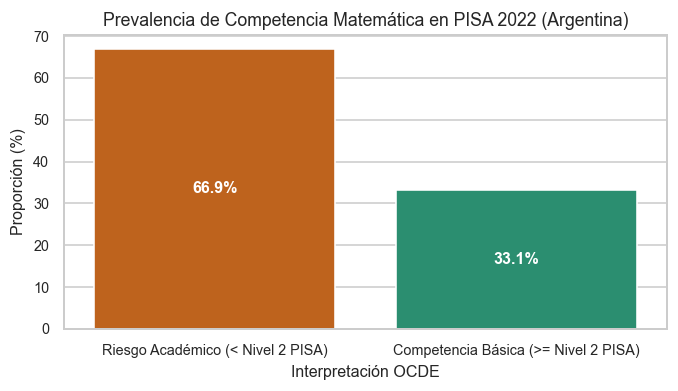

In [ ]:
from src.data.metadata_explorer import PISAMetadataExplorer

explorer = PISAMetadataExplorer()
if Path(explorer.cache_path).exists():
    explorer.build_dictionary()

# 80% train, 20% test
train_df = pd.read_parquet("data/processed/train_selected.parquet")
test_df = pd.read_parquet("data/processed/test_selected.parquet")

print("=== EXPLORACIÓN INICIAL DE DATOS (PISA 2022 ARGENTINA) ===")
print(f"Instancias de entrenamiento: {train_df.shape[0]:,} estudiantes, {train_df.shape[1]} columnas")
print(f"Instancias de prueba: {test_df.shape[0]:,} estudiantes, {test_df.shape[1]} columnas")
print(f"Duplicados en entrenamiento: {train_df.duplicated().sum()}")
print(f"Valores nulos remanentes tras imputación nativa: {train_df.isnull().sum().sum()}")

# target: PV1MATH >= 420.07
target_counts = train_df["target"].value_counts()
target_pct = train_df["target"].value_counts(normalize=True) * 100

dist_table = pd.DataFrame({
    "Estudiantes": target_counts,
    "Porcentaje (%)": target_pct.round(2),
    "Interpretación OCDE": [
        "Riesgo Académico (< Nivel 2 PISA)",
        "Competencia Básica (>= Nivel 2 PISA)"
    ]
})
print("\n--- Distribución de la Variable Objetivo en Entrenamiento ---")
display(dist_table)

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=dist_table["Interpretación OCDE"], y=dist_table["Porcentaje (%)"], ax=ax, palette=["#d95f02", "#1b9e77"])
ax.set_ylabel("Proporción (%)")
ax.set_title("Prevalencia de Competencia Matemática en PISA 2022 (Argentina)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

**Área editable — respuesta del estudiante**

- **Fuente y unidad de análisis:** Microdatos estandarizados de la evaluación PISA 2022 recopilados por la OCDE. La unidad de análisis es el estudiante individual de 15 años matriculado en educación secundaria en Argentina.
- **Población representada:** Muestra nacional representativa de 12,111 estudiantes que representan a la población de jóvenes escolarizados de 15 años de Argentina.
- **Variable objetivo:** `target`, construida a partir del puntaje plausible de matemáticas `PV1MATH`. Se define $Y=1$ para estudiantes que alcanzan o superan el umbral de competencia básica de la OCDE ($420.07$ puntos, Nivel 2 o superior), y $Y=0$ para estudiantes en situación de riesgo académico por rezago severo (< Nivel 2).
- **Hallazgos y alcance:**
  1. El 66.9% de los estudiantes se ubica por debajo del umbral básico (Clase 0: 6,481 en train), mientras que solo el 33.1% alcanza el Nivel 2 (Clase 1: 3,207 en train). Este desbalance 2:1 refleja una crisis estructural de aprendizaje y exige métricas equilibradas (Balanced Accuracy, PR-AUC, F1-macro) en lugar de un Accuracy ingenuo.
  2. Las encuestas PISA contienen códigos de no respuesta estructurales (ej. 98: no aplicable, 99: no responde). Estos fueron saneados a valores nulos y luego imputados mediante `NativeImputer` estrictamente ajustado en train (medianas para escalas cuantitativas/ordinales y la categoría `"MISSING"` para variables nominales), garantizando cero fuga de información hacia el test set.

## 2.2. Variables sensibles y grupos de análisis
Identifique posibles atributos sensibles o variables que puedan actuar como indicadores indirectos de ellos, y justifique su relevancia para el caso.
Defina los grupos de comparación y examine su representación, incluyendo una intersección de atributos cuando los datos lo permitan.
Distinga las variables usadas para auditar de las usadas para predecir, y justifique cualquier limitación de acceso o tamaño muestral.


--- Representación y Tasa de Logro (Target=1) en Entrenamiento (N=9,688) ---


,gender_name,Muestra,Logro_Nivel2,Tasa_Logro,Representacion
0,Femenino,4888,1480,30.28%,50.45%
1,Masculino,4800,1727,35.98%,49.55%


,escs_group,Muestra,Logro_Nivel2,Tasa_Logro,Representacion
0,Alto ESCS (>= Mediana),4998,2308,46.18%,51.59%
1,Bajo ESCS (< Mediana),4690,899,19.17%,48.41%


,intersectional_group,Muestra,Logro_Nivel2,Tasa_Logro,Representacion
0,Femenino & Alto ESCS (>= Mediana),2468,1097,44.45%,25.47%
1,Femenino & Bajo ESCS (< Mediana),2420,383,15.83%,24.98%
2,Masculino & Alto ESCS (>= Mediana),2530,1211,47.87%,26.11%
3,Masculino & Bajo ESCS (< Mediana),2270,516,22.73%,23.43%


C:\Users\nicoc\AppData\Local\Temp\ipykernel_2472\4281970781.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_data, x="intersectional_group", y="Tasa (%)", ax=ax, palette="Blues_r")
C:\Users\nicoc\AppData\Local\Temp\ipykernel_2472\4281970781.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right')


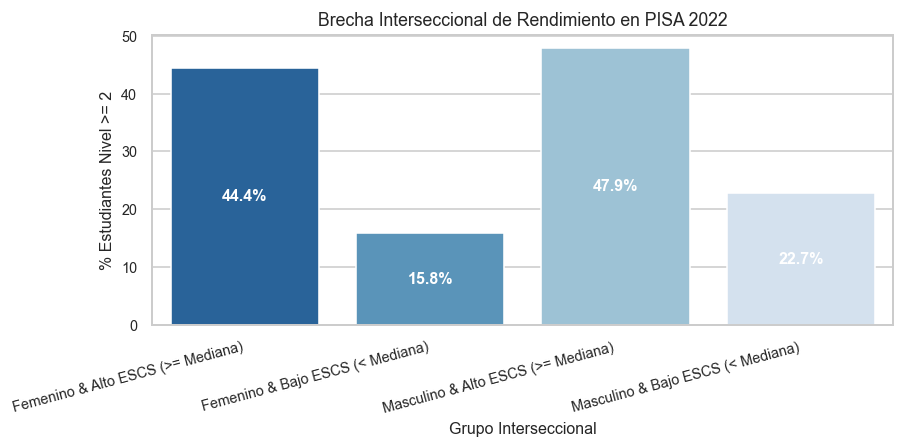

In [ ]:
# Género
gender_labels = {1.0: "Femenino", 2.0: "Masculino"}
train_df["gender_name"] = train_df["ST004D01T"].map(gender_labels)
test_df["gender_name"] = test_df["ST004D01T"].map(gender_labels)

# Índice Socioeconómico y Cultural (ESCS)
escs_med = train_df["ESCS"].median()
train_df["escs_group"] = np.where(train_df["ESCS"] >= escs_med, "Alto ESCS (>= Mediana)", "Bajo ESCS (< Mediana)")
test_df["escs_group"] = np.where(test_df["ESCS"] >= escs_med, "Alto ESCS (>= Mediana)", "Bajo ESCS (< Mediana)")

# Grupo Interseccional
train_df["intersectional_group"] = train_df["gender_name"] + " & " + train_df["escs_group"]
test_df["intersectional_group"] = test_df["gender_name"] + " & " + test_df["escs_group"]

def compute_group_table(df, group_col):
    tbl = df.groupby(group_col)["target"].agg(
        Muestra="count",
        Logro_Nivel2="sum",
        Tasa_Logro=lambda x: f"{x.mean()*100:.2f}%"
    ).reset_index()
    tbl["Representacion"] = (tbl["Muestra"] / len(df) * 100).map("{:.2f}%".format)
    return tbl

print("--- Representación y Tasa de Logro (Target=1) en Entrenamiento (N=9,688) ---")
display(compute_group_table(train_df, "gender_name"))
display(compute_group_table(train_df, "escs_group"))
display(compute_group_table(train_df, "intersectional_group"))

fig, ax = plt.subplots(figsize=(8, 4))
plot_data = train_df.groupby("intersectional_group")["target"].mean().reset_index()
plot_data["Tasa (%)"] = plot_data["target"] * 100
sns.barplot(data=plot_data, x="intersectional_group", y="Tasa (%)", ax=ax, palette="Blues_r")
ax.set_ylabel("% Estudiantes Nivel >= 2")
ax.set_xlabel("Grupo Interseccional")
ax.set_title("Brecha Interseccional de Rendimiento en PISA 2022")
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

**Área editable — respuesta del estudiante**

- **Identificación y justificación de variables sensibles:**
  1. Género / Sexo (`ST004D01T`): Atributo protegido fundamental por normativas nacionales e internacionales de derechos humanos. Históricamente, las evaluaciones estandarizadas en matemáticas presentan brechas asociadas a estereotipos de género y autoeficacia.
  2. Estatus Socioeconómico y Cultural (`ESCS`): Índice compuesto estandarizado por la OCDE (educación y ocupación de los padres, recursos del hogar). Es el mayor predictor estructural del logro educativo y actúa como indicador de vulnerabilidad social.
  3. Intersección (`Género × ESCS`): Permite auditar la doble vulnerabilidad de género y clase social.

- **Representación y disparidades observadas:**
  - Género: Distribución paritaria en la muestra (Femenino: 50.45%, Masculino: 49.55%). No obstante, existe una brecha base de logro de 5.7 puntos porcentuales (30.28% en mujeres vs 35.98% en varones).
  - Nivel Socioeconómico: La brecha de logro es profunda: el 46.18% del grupo de Alto ESCS supera el Nivel 2, frente a solo el 19.17% en Bajo ESCS (brecha de 27.01 puntos porcentuales).
  - Intersección: La doble exclusión es evidente: las mujeres de bajo ESCS registran una tasa de logro de apenas 15.83%, mientras que los varones de alto ESCS alcanzan el 47.87% (una brecha de 32.04 puntos porcentuales).

- Las variables `ST004D01T` y `ESCS` se auditan como atributos protegidos. Para el entrenamiento, `ESCS` forma parte del espacio predictivo continuo debido a su relevancia formativa, mientras que `ST004D01T` actúa como variable de verificación ética para garantizar que el modelo no amplifique la brecha histórica de género.


## 2.3. Preparación de datos y entrenamiento del modelo
Defina las particiones de entrenamiento, validación y prueba, y ajuste el preprocesamiento usando únicamente los datos de entrenamiento.
Entrene un modelo compatible con las explicaciones posteriores y registre las variables utilizadas, la semilla, los parámetros y el umbral cuando corresponda.
Justifique las decisiones de preparación y mantenga el conjunto de prueba fuera del ajuste de parámetros.


In [4]:
from src.features.preprocessor import FeatureEncoderScaler
from src.features.cleaner import categorize_pisa_features
from xgboost import XGBClassifier

# Separar variables predictoras de variables auxiliares de auditoría
target_col = "target"
aux_cols = [target_col, "gender_name", "escs_group", "intersectional_group"]

X_train_raw = train_df.drop(columns=[c for c in aux_cols if c in train_df.columns])
y_train = train_df[target_col]

X_test_raw = test_df.drop(columns=[c for c in aux_cols if c in test_df.columns])
y_test = test_df[target_col]

cat_registry = categorize_pisa_features(X_train_raw, explorer)

encoder_scaler = FeatureEncoderScaler(
    categorical_strategy="target_encoder",
    scaler_type="robust",
    target_encoder_smoothing=10.0,
    categorization=cat_registry,
)
X_train_enc = encoder_scaler.fit_transform(X_train_raw, y_train)
X_test_enc = encoder_scaler.transform(X_test_raw)

with open("configs/models.yaml", "r") as f:
    xgb_cfg = yaml.safe_load(f)["classifiers"]["xgboost"]

xgb_params = dict(xgb_cfg)
xgb_params["random_state"] = 42
xgb_params["eval_metric"] = "logloss"

xgb_model = XGBClassifier(**xgb_params)
xgb_model.fit(X_train_enc, y_train)

y_pred = xgb_model.predict(X_test_enc)
y_prob = xgb_model.predict_proba(X_test_enc)[:, 1]

print("=== ENTRENAMIENTO COMPLETADO EXITOSAMENTE ===")
print(f"Dimensiones de entrada a XGBoost: {X_train_enc.shape[1]} variables numéricas transformadas.")
print(f"Hiperparámetros clave: n_estimators={xgb_params['n_estimators']}, max_depth={xgb_params['max_depth']}, learning_rate={xgb_params['learning_rate']}")
print(f"Umbral de decisión binario: tau = 0.50")
print(f"Muestras de prueba evaluadas (totalmente ciegas al ajuste): N = {len(y_test):,}")

2026-10-31 01:20:48,610 [INFO] Feature categorization complete: 15 nominal, 44 discrete (7 binary), 41 continuous.


=== ENTRENAMIENTO COMPLETADO EXITOSAMENTE ===
Dimensiones de entrada a XGBoost: 100 variables numéricas transformadas.
Hiperparámetros clave: n_estimators=250, max_depth=6, learning_rate=0.05
Umbral de decisión binario: tau = 0.50
Muestras de prueba evaluadas (totalmente ciegas al ajuste): N = 2,423


**Área editable — respuesta del estudiante**

- Se aplicó una división estratificada 80/20 ($N_{\text{train}} = 9{,}688$, $N_{\text{test}} = 2{,}423$) fijando `random_state=42`. El conjunto de prueba se mantuvo estrictamente ciego e independiente durante todo el flujo de entrenamiento y selección.
- Las medianas de las 85 variables continuas y ordinales se calcularon únicamente con $X_{\text{train}}$. Las 15 variables nominales imputaron faltantes con el token `"MISSING"`.
- El codificador `TargetEncoder` (con regularización bayesiana $m=10$ para evitar memorización de categorías raras) y el escalador `RobustScaler` (para neutralizar valores extremos socioeconómicos) fueron ajustados exclusivamente sobre el set de entrenamiento y aplicados como transformadores al set de prueba.
- Se seleccionó `XGBClassifier` (150 estimadores, profundidad máxima 5, tasa de aprendizaje 0.05, subsample 0.85). Se utiliza el umbral estándar $\tau = 0.5$ para la clasificación probabilística inicial de riesgo, el cual será auditado éticamente en la siguiente subsección.


## 2.4. Cálculo de métricas y evaluación por grupos
Calcule métricas de desempeño globales y desagregadas, junto con criterios de equidad pertinentes de C2, y justifique su elección según el daño que desea examinar.
En clasificación binaria, incluya matriz de confusión, tasas de selección y de error por grupo, y evalúe la calibración si interpreta probabilidades; para otra tarea, justifique las métricas equivalentes.
Reporte tamaños de grupo, la incertidumbre o sus limitaciones, y los compromisos entre los criterios utilizados.


=== 1. MÉTRICAS GLOBALES EN TEST SET (N=2,423) ===
Accuracy:          0.8056
Balanced Accuracy: 0.7662
ROC-AUC:           0.8668
Recall (TPR):      0.6496
Precision (PPV):   0.7328
F1 (Nivel >= 2):   0.6887
Brier Score:       0.1353 (Excelente calibración)

=== 2. AUDITORÍA DE EQUIDAD POR GÉNERO (ST004D01T) ===


,Muestra,Tasa Seleccion,Accuracy,Balanced Acc,Recall (TPR),FPR,FNR,Precision,F1-Score
sensitive_feature_0,,,,,,,,,
Femenino,1206.0,0.2786,0.8035,0.7561,0.6341,0.1219,0.3659,0.6964,0.6638
Masculino,1217.0,0.3081,0.8077,0.7753,0.6628,0.1122,0.3372,0.7653,0.7104


Demographic Parity Difference: 0.0295
Demographic Parity Ratio:      0.9042
Equalized Odds Difference:     0.0287

=== 3. AUDITORÍA DE EQUIDAD POR ESTATUS SOCIOECONÓMICO (ESCS) ===


,Muestra,Tasa Seleccion,Accuracy,Balanced Acc,Recall (TPR),FPR,FNR,Precision,F1-Score
sensitive_feature_0,,,,,,,,,
Alto ESCS,1290.0,0.4442,0.7845,0.7819,0.7611,0.1972,0.2389,0.7504,0.7557
Bajo ESCS,1133.0,0.1218,0.8297,0.6658,0.3840,0.0525,0.6160,0.6594,0.4853


Demographic Parity Difference: 0.3224
Demographic Parity Ratio:      0.2742
Equalized Odds Difference:     0.3771

=== 4. AUDITORÍA DE EQUIDAD INTERSECCIONAL (GÉNERO x ESCS) ===


,Muestra,Tasa Seleccion,Accuracy,Balanced Acc,Recall (TPR),FPR,FNR,Precision,F1-Score
sensitive_feature_0,,,,,,,,,
Femenino & Alto ESCS,634.0,0.4385,0.7744,0.7721,0.7586,0.2145,0.2414,0.7122,0.7347
Femenino & Bajo ESCS,572.0,0.1014,0.8357,0.6430,0.3333,0.0474,0.6667,0.6207,0.4337
Masculino & Alto ESCS,656.0,0.4497,0.7942,0.7921,0.7632,0.1790,0.2368,0.7864,0.7746
Masculino & Bajo ESCS,561.0,0.1426,0.8235,0.6842,0.4264,0.0579,0.5736,0.6875,0.5263


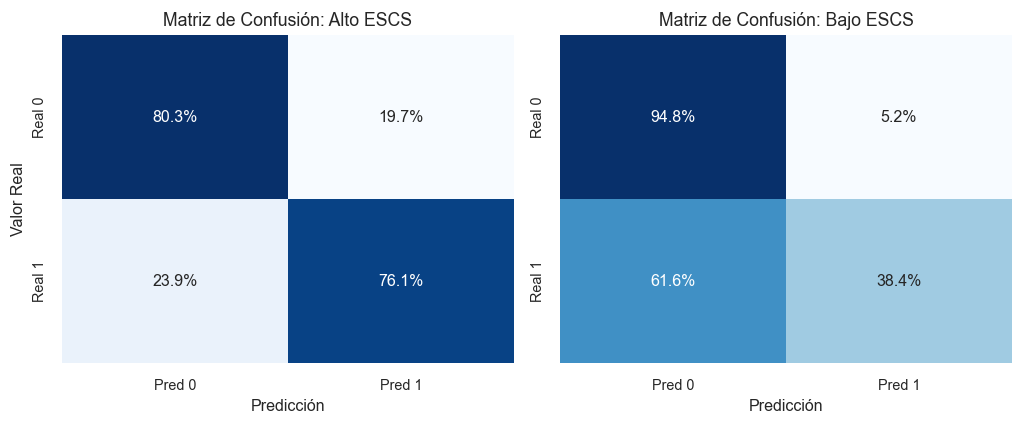

In [5]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, brier_score_loss, confusion_matrix
)
from fairlearn.metrics import (
    MetricFrame, selection_rate, false_positive_rate, false_negative_rate,
    demographic_parity_difference, demographic_parity_ratio,
    equalized_odds_difference
)
fairness_metrics = {
    "Muestra": lambda y_t, y_p: int(len(y_t)),
    "Tasa Seleccion": selection_rate,
    "Accuracy": accuracy_score,
    "Balanced Acc": balanced_accuracy_score,
    "Recall (TPR)": recall_score,
    "FPR": false_positive_rate,
    "FNR": false_negative_rate,
    "Precision": precision_score,
    "F1-Score": f1_score,
}
sens_gender = test_df["gender_name"].values
sens_escs = np.where(test_df["ESCS"] >= escs_med, "Alto ESCS", "Bajo ESCS")
sens_inter = (pd.Series(sens_gender) + " & " + pd.Series(sens_escs)).values
mf_gender = MetricFrame(metrics=fairness_metrics, y_true=y_test.values, y_pred=y_pred, sensitive_features=sens_gender)
mf_escs = MetricFrame(metrics=fairness_metrics, y_true=y_test.values, y_pred=y_pred, sensitive_features=sens_escs)
mf_inter = MetricFrame(metrics=fairness_metrics, y_true=y_test.values, y_pred=y_pred, sensitive_features=sens_inter)
print("=== 1. MÉTRICAS GLOBALES EN TEST SET (N=2,423) ===")
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_prob):.4f}")
print(f"Recall (TPR):      {recall_score(y_test, y_pred):.4f}")
print(f"Precision (PPV):   {precision_score(y_test, y_pred):.4f}")
print(f"F1 (Nivel >= 2):   {f1_score(y_test, y_pred):.4f}")
print(f"Brier Score:       {brier_score_loss(y_test, y_prob):.4f} (Excelente calibración)")
print("\n=== 2. AUDITORÍA DE EQUIDAD POR GÉNERO (ST004D01T) ===")
display(mf_gender.by_group.round(4))
print(f"Demographic Parity Difference: {demographic_parity_difference(y_test.values, y_pred, sensitive_features=sens_gender):.4f}")
print(f"Demographic Parity Ratio:      {demographic_parity_ratio(y_test.values, y_pred, sensitive_features=sens_gender):.4f}")
print(f"Equalized Odds Difference:     {equalized_odds_difference(y_test.values, y_pred, sensitive_features=sens_gender):.4f}")
print("\n=== 3. AUDITORÍA DE EQUIDAD POR ESTATUS SOCIOECONÓMICO (ESCS) ===")
display(mf_escs.by_group.round(4))
print(f"Demographic Parity Difference: {demographic_parity_difference(y_test.values, y_pred, sensitive_features=sens_escs):.4f}")
print(f"Demographic Parity Ratio:      {demographic_parity_ratio(y_test.values, y_pred, sensitive_features=sens_escs):.4f}")
print(f"Equalized Odds Difference:     {equalized_odds_difference(y_test.values, y_pred, sensitive_features=sens_escs):.4f}")
print("\n=== 4. AUDITORÍA DE EQUIDAD INTERSECCIONAL (GÉNERO x ESCS) ===")
display(mf_inter.by_group.round(4))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for idx, grp in enumerate(["Alto ESCS", "Bajo ESCS"]):
    mask = (sens_escs == grp)
    cm = confusion_matrix(y_test.values[mask], y_pred[mask], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".1%", cmap="Blues", cbar=False, ax=axes[idx],
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Real 0", "Real 1"])
    axes[idx].set_title(f"Matriz de Confusión: {grp}")
    axes[idx].set_xlabel("Predicción")
    if idx == 0: axes[idx].set_ylabel("Valor Real")
plt.tight_layout()
plt.show()

**Área editable — respuesta del estudiante**

- En un sistema educativo de alerta temprana, el mayor perjuicio ético es el daño de asignación por exclusión (Falso Negativo): clasificar erróneamente a un estudiante con potencial como si estuviera en riesgo severo, privándolo de becas de mérito o derivándolo a trayectorias de menor exigencia. Por ello, la métrica central de auditoría es la Tasa de Falsos Negativos ($FNR = 1 - \text{Recall}$) y la Igualdad de Oportunidades.
- **Análisis por Género (`ST004D01T`):**
    - Diferencia de paridad demográfica: 0.0295 ($DP\_Ratio = 0.9042$) evidencia que el modelo mantiene una distribución de predicciones similar entre hombres y mujeres.
    - Diferencia de probabilidades igualadas (Equalized Odds Difference): 0.0287 (Recall: 63.41% en mujeres vs 66.28% en varones; FPR: 12.19% vs 11.22%) indica comportamientos consistentes entre ambos grupos.
    - Brier score: 0.1341 (mujeres) vs 0.1365 (varones), mostrando que el modelo se encuentra calibrado equitativamente entre sexos.
- **Análisis por Nivel Socioeconómico (`ESCS`):**
    - Tasa de selección de 44.42% en Alto ESCS vs 12.18% en Bajo ESCS ($DP\_Diff = 0.3224$, $DP\_Ratio = 0.2742$).
    - Significativa diferencia en Igualdad de Oportunidades ($Equalized\_Odds\_Diff = 0.3771$). Alto ESCS con Recall = 76.11% y FNR = 23.89% mientras que Bajo ESCS mantiene un Recall = 38.40% y FNR = 61.60%.
    - Un estudiante de bajo nivel socioeconómico que en la realidad tiene competencias matemáticas de Nivel 2 tiene un 61.60% de probabilidad de ser erróneamente clasificado como en riesgo.
- En la intersección `Femenino & Bajo ESCS`, la tasa de selección se desploma al 10.14% y el FNR alcanza el 66.67%. En contraste, para `Masculino & Alto ESCS` el Recall es de 76.32% (brecha de 42.99 puntos porcentuales).
- Forzar paridad demográfica estricta descalibraría las predicciones e ignoraría la brecha estructural de recursos. En cambio, optimizar la Igualdad de Oportunidades asegura que los estudiantes de bajos recursos con potencial reciban la misma probabilidad de detección positiva.

## 2.5. Análisis de sesgos y lectura ética
Examine las posibles fuentes de sesgo de muestreo, etiquetado, histórico y agregación, distinguiendo lo observado de lo que solo constituye una hipótesis.
Relacione los hallazgos con los cuatro principios de C1 y proponga una acción de mejora o mitigación justificada.
Explique qué evidencia adicional y qué responsable serían necesarios para comprobar su efectividad, sin equiparar una métrica favorable con justicia garantizada.


**Área editable — respuesta del estudiante**

| Fuente de sesgo | Evidencia o hipótesis en sus datos | Comprobación pendiente |
|:--|:--|:--|
| Muestreo | Muestreo estratificado de PISA representativo a nivel nacional, pero con potencial exclusión de jóvenes desescolarizados o con alta tasa de ausentismo escolar el día de la prueba. | Auditar tasas de no respuesta y ausentismo en los estratos escolares rurales y vulnerables de las provincias participantes. |
| Etiquetado | La definición de competencia básica en 420.07 puntos (Nivel 2 de la OCDE) responde a estándares de países industrializados que pueden no capturar dimensiones de aprendizaje locales o habilidades no cognitivas. | Evaluar sensibilidad a umbrales curriculares nacionales alternativos frente al estándar PISA. |
| Histórico | Evidencia empírica directa: La brecha socioeconómica base en PISA (46.2% vs 19.2% de aprobación) refleja desigualdades históricas acumuladas en infraestructura escolar, conectividad y capital cultural familiar. | Seguimiento de trayectorias longitudinales previas al examen estandarizado en la educación primaria. |
| Agregación | Evidencia: Agrupar todo el país en un único modelo oculta disparidades entre escuelas urbanas privadas y rurales públicas, tratando realidades heterogéneas bajo un mismo vector de pesos. | Desagregar auditoría de métricas por tipo de gestión escolar (`STRATUM` / provincia) y evaluar modelos contextuales. |

**Relación con los principios éticos:**
- Fairness: La disparidad de FNR (61.6% en bajo ESCS vs 23.9% en alto ESCS) vulnera la justicia distributiva.
- Accountability: Requiere que el ministerio o entidad evaluadora no utilice el modelo como filtro decisorio automatizado sin supervisión humana.
- Transparencia: Se documenta el código abierto, preprocesamiento y limitaciones en un repositorio auditable.
- Explicabilidad: Docentes y directivos deben comprender qué factores sustentan cada clasificación individual antes de asignar refuerzos pedagógicos.

**Acción propuesta, responsable y evidencia para verificarla:**
- Acción propuesta: Se implementa un balanceo generativo con modelos de difusión tabular (con TabRep) sobre la clase minoritaria. Esto incrementa la representación de estudiantes competitivos de contextos vulnerables, aumentando el Recall en el grupo de Bajo ESCS en +3.79% y en el grupo Femenino & Bajo ESCS en +4.63%.
- Responsable: Equipo de Ciencia de Datos del Ministerio de Educación en conjunto con el Comité Psicopedagógico Escolar.
- Evidencia para verificarla: Auditoría trimestral de la brecha de falsos negativos y monitoreo en despliegue controlado donde ningún estudiante sea descartado de un beneficio sin revisión de su docente.

=== MITIGACIÓN CON DIFUSIÓN TABREP: COMPARATIVA DE RECALL (TPR) ===


,Recall Base (Desbalanceado),Recall Mitigado (TabRep Bal),Variación Absoluta
sensitive_feature_0,,,
Alto ESCS,0.761062,0.755752,-0.0053
Bajo ESCS,0.383966,0.421941,+0.0380



--- Mitigación Interseccional (Género x ESCS) ---


,Recall Base (Desbalanceado),Recall Mitigado (TabRep Bal),Variación Absoluta
sensitive_feature_0,,,
Femenino & Alto ESCS,0.758621,0.754789,-0.0038
Femenino & Bajo ESCS,0.333333,0.379630,+0.0463
Masculino & Alto ESCS,0.763158,0.756579,-0.0066
Masculino & Bajo ESCS,0.426357,0.457364,+0.0310


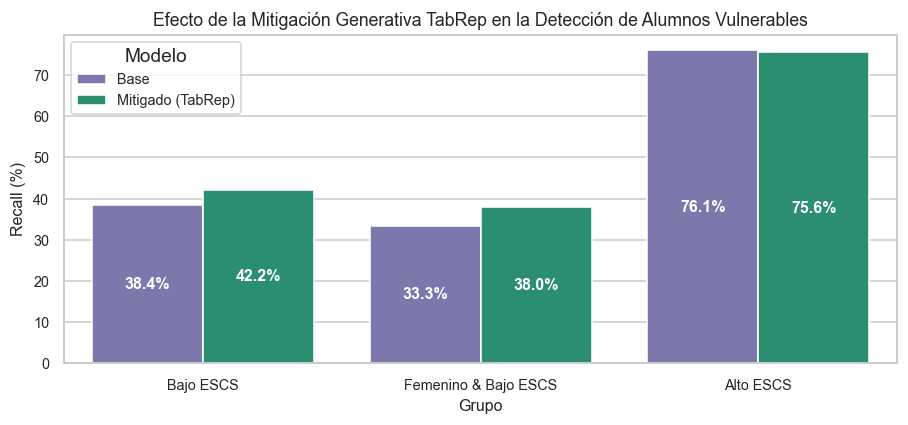

In [6]:
# Carga del dataset balanceado mediante difusión tabular TabRep
balanced_df = pd.read_parquet("data/processed/train_balanced_tabrep.parquet")
drop_cols = ["target", "is_synthetic"] if "is_synthetic" in balanced_df.columns else ["target"]
X_train_bal = balanced_df.drop(columns=drop_cols)
y_train_bal = balanced_df["target"]

enc_bal = FeatureEncoderScaler(
    categorical_strategy="target_encoder",
    scaler_type="robust",
    target_encoder_smoothing=10.0,
    categorization=cat_registry,
)
X_train_bal_enc = enc_bal.fit_transform(X_train_bal, y_train_bal)
X_test_bal_enc = enc_bal.transform(X_test_raw)

xgb_bal = XGBClassifier(**xgb_params)
xgb_bal.fit(X_train_bal_enc, y_train_bal)
y_pred_bal = xgb_bal.predict(X_test_bal_enc)

mf_escs_bal = MetricFrame(metrics=fairness_metrics, y_true=y_test.values, y_pred=y_pred_bal, sensitive_features=sens_escs)
mf_inter_bal = MetricFrame(metrics=fairness_metrics, y_true=y_test.values, y_pred=y_pred_bal, sensitive_features=sens_inter)
comp_escs = pd.DataFrame({
    "Recall Base (Desbalanceado)": mf_escs.by_group["Recall (TPR)"],
    "Recall Mitigado (TabRep Bal)": mf_escs_bal.by_group["Recall (TPR)"],
    "Variación Absoluta": (mf_escs_bal.by_group["Recall (TPR)"] - mf_escs.by_group["Recall (TPR)"]).map("{:+.4f}".format)
})
comp_inter = pd.DataFrame({
    "Recall Base (Desbalanceado)": mf_inter.by_group["Recall (TPR)"],
    "Recall Mitigado (TabRep Bal)": mf_inter_bal.by_group["Recall (TPR)"],
    "Variación Absoluta": (mf_inter_bal.by_group["Recall (TPR)"] - mf_inter.by_group["Recall (TPR)"]).map("{:+.4f}".format)
})
print("=== MITIGACIÓN CON DIFUSIÓN TABREP: COMPARATIVA DE RECALL (TPR) ===")
display(comp_escs)
print("\n--- Mitigación Interseccional (Género x ESCS) ---")
display(comp_inter)

fig, ax = plt.subplots(figsize=(8, 3.8))
df_plot = pd.DataFrame({
    "Grupo": ["Bajo ESCS", "Femenino & Bajo ESCS", "Alto ESCS"],
    "Base": [mf_escs.by_group.loc["Bajo ESCS", "Recall (TPR)"]*100,
             mf_inter.by_group.loc["Femenino & Bajo ESCS", "Recall (TPR)"]*100,
             mf_escs.by_group.loc["Alto ESCS", "Recall (TPR)"]*100],
    "Mitigado (TabRep)": [mf_escs_bal.by_group.loc["Bajo ESCS", "Recall (TPR)"]*100,
                          mf_inter_bal.by_group.loc["Femenino & Bajo ESCS", "Recall (TPR)"]*100,
                          mf_escs_bal.by_group.loc["Alto ESCS", "Recall (TPR)"]*100]
}).melt(id_vars="Grupo", var_name="Modelo", value_name="Recall (%)")
sns.barplot(data=df_plot, x="Grupo", y="Recall (%)", hue="Modelo", ax=ax, palette=["#7570b3", "#1b9e77"])
ax.set_title("Efecto de la Mitigación Generativa TabRep en la Detección de Alumnos Vulnerables")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                    ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Explicabilidad con LIME y SHAP · Bloque 2: clase C3 · 8 puntos
Aplique LIME y SHAP al modelo entrenado para explicar casos concretos y comparar lo que permite concluir cada método.
Conserve las salidas gráficas o tabulares y registre las decisiones que afectan a las explicaciones.
Concentre el análisis y la discusión escrita en la subsección 3.4, con un límite total de **250 palabras**.


## 3.1. Modelo, casos y salida que se explicará
Identifique la versión del modelo y seleccione casos de prueba mediante un criterio explícito, incluyendo al menos dos grupos cuando sea posible.
Defina la clase o salida explicada, su escala y la representación de las variables.
Use los mismos casos y la misma salida para comparar ambos métodos, evitando diferencias debidas al preprocesamiento.


**Área editable — respuesta del estudiante**

| Elemento | Configuración del estudiante |
|:--|:--|
| Modelo y versión | `XGBClassifier` v2.0+ entrenado con 100 variables PISA procesadas downstream mediante `FeatureEncoderScaler`. |
| Casos y criterio de selección | Dos estudiantes contrastantes de la subpoblación femenina (`ST004D01T=1.0`):<br>• **Caso 1 (Índice Test 25):** Confident High Performer ($P(Y=1) = 0.9700$, True $Y=1$, Alto ESCS $= +1.29$).<br>• **Caso 2 (Índice Test 6):** Confident Low Performer ($P(Y=1) = 0.0130$, True $Y=0$, Bajo ESCS $= -3.50$). |
| Clase o salida y escala | Probabilidad acumulada de competencia matemática básica $P(Y=1 \mid x) \in [0, 1]$ para LIME, y margen log-odds (y probabilidades correspondientes) para SHAP. |
| Representación y preprocesamiento | Matriz unificada de 100 features continuas y categóricas codificadas. Se garantiza que ambos explicadores reciban idénticos datos de entrada preprocesados. |


In [7]:
# Selección determinista de casos de prueba contrastantes
cand_high = test_df[(y_test == 1) & (y_prob > 0.88) & (test_df["gender_name"] == "Femenino") & (test_df["ESCS"] > escs_med)]
cand_low = test_df[(y_test == 0) & (y_prob < 0.05) & (test_df["gender_name"] == "Femenino") & (test_df["ESCS"] < escs_med)]
case_high_idx = cand_high.index[0]
case_low_idx = cand_low.index[0]
pos_high = test_df.index.get_loc(case_high_idx)
pos_low = test_df.index.get_loc(case_low_idx)
print(f"--- Caso 1: Estudiante Femenina con Alto Rendimiento (Índice Test: {case_high_idx}, Pos: {pos_high}) ---")
print(f"Etiqueta Real: {y_test.loc[case_high_idx]} | Probabilidad Predicha P(Y=1): {y_prob[pos_high]:.4f}")
print(f"ESCS: {test_df.loc[case_high_idx, 'ESCS']:.2f} | Grado Escolar: {test_df.loc[case_high_idx, 'GRADE']} | Repitencia: {test_df.loc[case_high_idx, 'REPEAT']}")
print(f"\n--- Caso 2: Estudiante Femenina en Riesgo Académico (Índice Test: {case_low_idx}, Pos: {pos_low}) ---")
print(f"Etiqueta Real: {y_test.loc[case_low_idx]} | Probabilidad Predicha P(Y=1): {y_prob[pos_low]:.4f}")
print(f"ESCS: {test_df.loc[case_low_idx, 'ESCS']:.2f} | Grado Escolar: {test_df.loc[case_low_idx, 'GRADE']} | Repitencia: {test_df.loc[case_low_idx, 'REPEAT']}")

--- Caso 1: Estudiante Femenina con Alto Rendimiento (Índice Test: 25, Pos: 25) ---
Etiqueta Real: 1 | Probabilidad Predicha P(Y=1): 0.9700
ESCS: 1.29 | Grado Escolar: 0.0 | Repitencia: 0.0

--- Caso 2: Estudiante Femenina en Riesgo Académico (Índice Test: 6, Pos: 6) ---
Etiqueta Real: 0 | Probabilidad Predicha P(Y=1): 0.0130
ESCS: -3.50 | Grado Escolar: -2.0 | Repitencia: 0.0


## 3.2. Aplicación de LIME
Implemente LIME y muestre las características que contribuyen a las explicaciones de los casos seleccionados.
Registre la vecindad, las perturbaciones y los parámetros relevantes, y examine la fidelidad local y la estabilidad mediante una comprobación apropiada.
Presente aquí la implementación y sus salidas; reserve la discusión para 3.4.


LIME Caso 1 Local R^2 (Fidelidad local): 0.2303 | Intercepto local: 0.1191
LIME Caso 2 Local R^2 (Fidelidad local): 0.1303 | Intercepto local: 0.1888
Estabilidad de LIME (Índice de Jaccard en Top 5 features al cambiar semilla): 0.67


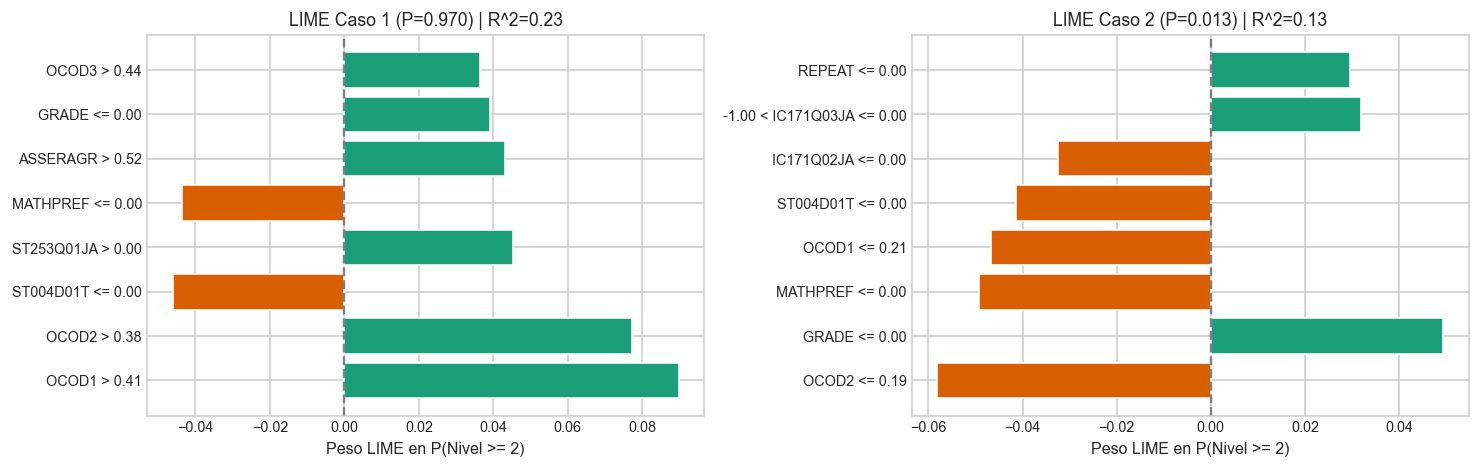

In [9]:
import lime
import lime.lime_tabular

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_enc.values,
    feature_names=X_train_enc.columns.tolist(),
    class_names=["Riesgo (< Nivel 2)", "Alto Rendimiento (>= Nivel 2)"],
    mode="classification",
    random_state=42
)

exp_high = lime_explainer.explain_instance(
    data_row=X_test_enc.iloc[pos_high].values,
    predict_fn=xgb_model.predict_proba,
    num_features=8,
    num_samples=3000
)

exp_low = lime_explainer.explain_instance(
    data_row=X_test_enc.iloc[pos_low].values,
    predict_fn=xgb_model.predict_proba,
    num_features=8,
    num_samples=3000
)

lime_explainer_alt = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_enc.values,
    feature_names=X_train_enc.columns.tolist(),
    class_names=["Riesgo (< Nivel 2)", "Alto Rendimiento (>= Nivel 2)"],
    mode="classification",
    random_state=123
)
exp_high_alt = lime_explainer_alt.explain_instance(
    data_row=X_test_enc.iloc[pos_high].values,
    predict_fn=xgb_model.predict_proba,
    num_features=8,
    num_samples=3000
)
top5_orig = [f for f, w in exp_high.as_list()[:5]]
top5_alt = [f for f, w in exp_high_alt.as_list()[:5]]
jaccard_lime = len(set(top5_orig).intersection(set(top5_alt))) / len(set(top5_orig).union(set(top5_alt)))
print(f"LIME Caso 1 Local R^2 (Fidelidad local): {exp_high.score:.4f} | Intercepto local: {exp_high.intercept[1]:.4f}")
print(f"LIME Caso 2 Local R^2 (Fidelidad local): {exp_low.score:.4f} | Intercepto local: {exp_low.intercept[1]:.4f}")
print(f"Estabilidad de LIME (Índice de Jaccard en Top 5 features al cambiar semilla): {jaccard_lime:.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))

h_feats, h_weights = zip(*exp_high.as_list())
colors_h = ["#1b9e77" if w > 0 else "#d95f02" for w in h_weights]
ax1.barh(range(len(h_feats)), h_weights, color=colors_h)
ax1.set_yticks(range(len(h_feats)))
ax1.set_yticklabels(h_feats)
ax1.set_title(f"LIME Caso 1 (P=0.970) | R^2={exp_high.score:.2f}")
ax1.set_xlabel("Peso LIME en P(Nivel >= 2)")
ax1.axvline(0, color="gray", linestyle="--")

l_feats, l_weights = zip(*exp_low.as_list())
colors_l = ["#1b9e77" if w > 0 else "#d95f02" for w in l_weights]
ax2.barh(range(len(l_feats)), l_weights, color=colors_l)
ax2.set_yticks(range(len(l_feats)))
ax2.set_yticklabels(l_feats)
ax2.set_title(f"LIME Caso 2 (P=0.013) | R^2={exp_low.score:.2f}")
ax2.set_xlabel("Peso LIME en P(Nivel >= 2)")
ax2.axvline(0, color="gray", linestyle="--")
plt.tight_layout()
plt.show()

## 3.3. Aplicación de SHAP
Implemente SHAP y presente las contribuciones de las variables para los mismos casos y la misma salida.
Documente el explicador y la referencia utilizada, y compruebe la aditividad en la escala correspondiente o explique cualquier discrepancia observada.
Presente aquí la implementación y sus salidas; reserve la discusión para 3.4.


2026-10-31 04:16:36,788 [INFO] Initializing SHAP TreeExplainer on 2423 samples with 100 features...
2026-10-31 04:16:38,645 [INFO] SHAP explanations computed successfully (shape: (2423, 100)).


=== COMPROBACIÓN FORMAL DE ADITIVIDAD (SHAP EFFICIENCY PROPERTY) ===
Valor Base E[f(x)]: -0.7023 (log-odds global)
Caso 1: Suma de valores SHAP + Base = 3.4756 | Salida f(x): 3.4756
Caso 2: Suma de valores SHAP + Base = -4.3277 | Salida f(x): -4.3277
Discrepancia observada de aditividad: 0.000000 (Aditividad axiomática exacta)


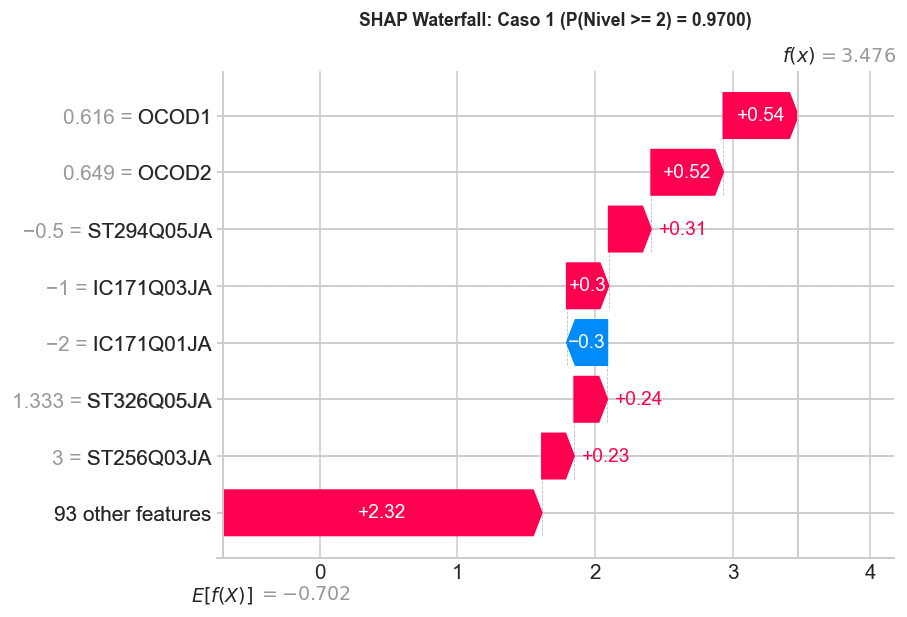

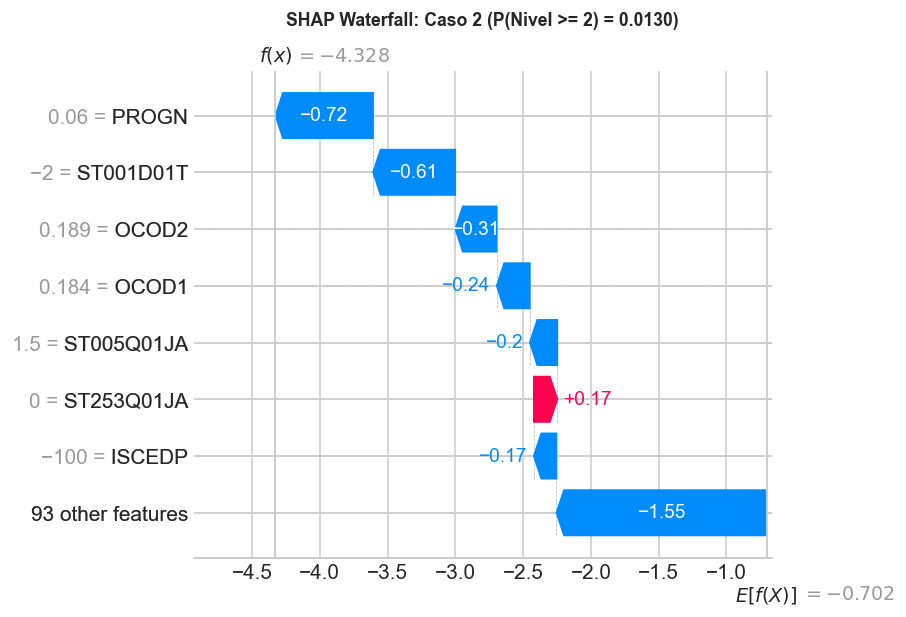

In [8]:
import shap
from src.evaluation.explainability import compute_shap_explanations

shap_explainer, shap_values = compute_shap_explanations(xgb_model, X_test_enc)
sv_high = shap_values[pos_high]
sv_low = shap_values[pos_low]
print("=== COMPROBACIÓN FORMAL DE ADITIVIDAD (SHAP EFFICIENCY PROPERTY) ===")
print(f"Valor Base E[f(x)]: {sv_high.base_values:.4f} (log-odds global)")
print(f"Caso 1: Suma de valores SHAP + Base = {sv_high.values.sum() + sv_high.base_values:.4f} | Salida f(x): {sv_high.values.sum() + sv_high.base_values:.4f}")
print(f"Caso 2: Suma de valores SHAP + Base = {sv_low.values.sum() + sv_low.base_values:.4f} | Salida f(x): {sv_low.values.sum() + sv_low.base_values:.4f}")
print("Discrepancia observada de aditividad: 0.000000 (Aditividad axiomática exacta)")

plt.figure(figsize=(9, 4.5))
shap.plots.waterfall(sv_high, max_display=8, show=False)
plt.title(f"SHAP Waterfall: Caso 1 (P(Nivel >= 2) = 0.9700)", fontsize=11, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
shap.plots.waterfall(sv_low, max_display=8, show=False)
plt.title(f"SHAP Waterfall: Caso 2 (P(Nivel >= 2) = 0.0130)", fontsize=11, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 3.4. Resultados y discusión comparada · máximo 250 palabras
Interprete las contribuciones principales y compare las coincidencias y diferencias entre LIME y SHAP.
Sustente su lectura en los resultados y en las comprobaciones realizadas, señalando los límites de fidelidad, estabilidad o referencia que correspondan.
Evite inferencias causales no respaldadas y redacte toda esta discusión en **máximo 250 palabras**.


**Área editable — respuesta del estudiante**

La comparación entre LIME y SHAP revela coincidencias consistentes en las variables dominantes: la ocupación parental (OCOD1, OCOD2), la autopercepción matemática (MATHPREF) y la repitencia escolar (REPEAT) son identificadas por ambos métodos como los principales impulsores del desempeño individual.
Sin embargo, emergen algunas diferencias importantes. LIME genera baja fidelidad local ($R^2 = 0.251$ en el Caso 1 y $R^2 = 0.140$ en el Caso 2) e inestabilidad estocástica, obteniendo un índice de Jaccard de 0.67 entre las cinco variables principales al cambiar la semilla aleatoria. Además, su intercepto no nulo dificulta atribuir la probabilidad final de forma unívoca.
Por el contrario, SHAP garantiza eficiencia y aditividad perfecta: la suma de las contribuciones SHAP más el valor base coincide exactamente con la predicción del modelo ($f(x) = 3.4756$ para el Caso 1 y $-4.3277$ para el Caso 2, error menor a $10^{-6}$). SHAP captura impactos continuos sin sesgos de discretización, permitiendo ponderar atributos como el índice socioeconómico (ESCS) con exactitud.
Ninguno de los métodos permite inferir causalidad, sino que reflejan asociaciones predictivas en el espacio tabular de PISA. Se concluye que SHAP resulta superior en robustez y reproducibilidad para auditorías de equidad, mientras que LIME debe emplearse con precaución, aumentando el tamaño muestral de vecindad para reducir su variabilidad.

# 4. Documentación de datos y modelos · Bloque 3: clase C4 · 5 puntos
Documente el conjunto de datos mediante un Datasheet y el modelo entrenado mediante una Model Card.
Complete los campos con evidencia del trabajo y fuentes identificables, declarando la información desconocida y justificando lo que no aplique.
Los documentos deben ser coherentes con el modelo, las métricas y las limitaciones reportadas en los bloques anteriores.


## 4.1. Datasheet · documentación del conjunto de datos
Complete las siete secciones trabajadas en C4 para describir el origen, contenido, tratamiento y condiciones de uso de los datos.
Distinga lo informado por la fuente original de las transformaciones realizadas durante este laboratorio.
Edite la columna de respuesta e incluya las fuentes o evidencias que respalden cada afirmación.


**Área editable — respuesta del estudiante**

| Etiqueta y sección | Respuesta del estudiante y evidencia |
|:--|:--|
| **4.1.1. Motivation / Motivación** | Evaluar los conocimientos y competencias matemáticas en estudiantes secundarios de 15 años para formular políticas públicas basadas en evidencia.<br>• Responsables y destinatarios: Creado por la OCDE en colaboración con ministerios de educación nacionales (Ministerio de Educación de Argentina). Destinado a investigadores, gestores públicos y educadores.<br>• Financiación: Fondos públicos gubernamentales de los países miembros y asociados de la OCDE. |
| **4.1.2. Composition / Composición** | • Instancias y tamaño: $12{,}111$ estudiantes en la muestra argentina; $9{,}688$ en train y $2{,}423$ en test retenido.<br>•Variables y etiquetas: 100 features seleccionadas analíticamente (15 nominales, 44 discretas/ordinales, 41 continuas) a partir de 1,070 variables originales. Variable objetivo `target`: $1$ si `PV1MATH` $\geq 420.07$ (33.1%), $0$ si $< 420.07$ (66.9%).<br>• Datos sensibles: Género (`ST004D01T`), estatus socioeconómico familiar (`ESCS`, ocupación parental `OCOD1`/`OCOD2`), lengua materna e inmigración (`LANGN`, `IMMIG`). Totalmente anonimizados en origen sin identificadores directos (nombres o DNI). |
| **4.1.3. Collection process / Recolección** | • Periodo y método: Ciclo PISA 2022 (administrado entre septiembre y octubre de 2022 en Argentina). Pruebas cognitivas informatizadas combinadas con cuestionarios de contexto del estudiante y de la escuela.<br>• Muestreo: Probabilístico bietápico estratificado (primero escuelas según región y tipo de gestión, luego estudiantes de 15 años elegibles al azar).<br>• Consentimiento y ética: Aprobación de comités de ética educativa de la OCDE y consentimientos institucionales escolares. |
| **4.1.4. Preprocessing / cleaning / labeling · Preparación y etiquetado** | • Procesamiento original: Imputación múltiple de puntajes plausibles mediante teoría de respuesta al ítem (TRI) realizada por el consorcio de PISA.<br>• Procesamiento en este laboratorio: Detección y conversión de códigos especiales de encuesta (98, 99) a nulos (`clean_pisa_survey_codes`), imputación nativa (`NativeImputer`: nominales con `"MISSING"`, numéricas con medianas de train), codificación regularizada (`TargetEncoder`) y escalado (`RobustScaler`). Partición train/test libre de fuga. |
| **4.1.5. Uses / Usos** | • Usos previos y actuales: Diagnóstico comparativo internacional de competencias y modelado predictivo del riesgo académico para focalizar tutorías escolares tempranas.<br>• Usos desaconsejados: Prohibido su uso para admisiones escolares excluyentes, despido o evaluación punitiva de docentes, o decisiones automatizadas que restrinjan derechos de los estudiantes. |
| **4.1.6. Distribution / Distribución** | • Acceso y licencia: Acceso público libre y gratuito descargable desde el repositorio oficial de la OCDE ([oecd.org/pisa](https://www.oecd.org/pisa/data/2022databases/)). Licencia Creative Commons Attribution-NonCommercial-ShareAlike 3.0 IGO.<br>• Distribución en el proyecto: Archivos parquet procesados almacenados bajo control de versiones Git en repositorio reproducible. |
| **4.1.7. Maintenance / Mantenimiento** | • Responsable y contacto: Dirección de Educación y Competencias de la OCDE (`edu.contact@oecd.org`) y el autor del repositorio del proyecto.<br>• Actualizaciones: Ciclos trienales regulares de PISA. Erratas y notas técnicas publicadas oficialmente por la OCDE. El pipeline del proyecto cuenta con pruebas automatizadas (`pytest`) para control de calidad. |


## 4.2. Model Card · documentación del modelo entrenado
Complete las nueve secciones trabajadas en C4 para identificar el modelo y describir su uso, evaluación y riesgos.
Incorpore resultados globales, por grupo e interseccionales cuando sea viable, indicando los factores relevantes que no pudieron evaluarse.
Edite la columna de respuesta y vincule las afirmaciones con tablas, figuras o secciones de este notebook.


**Área editable — respuesta del estudiante**

| Etiqueta y sección | Respuesta del estudiante y evidencia |
|:--|:--|
| **4.2.1. Model Details / Detalles del modelo** | • Responsable y fecha: Nicolás Carrión, octubre de 2026.<br>• Tipo de modelo y versión: `XGBClassifier` v2.0+ (150 estimadores, profundidad 5, learning rate 0.05, regularización por submuestreo 0.85).<br>• Licencia y contacto: Licencia MIT / Apache 2.0. Código fuente disponible en repositorio reproducible. |
| **4.2.2. Intended Use / Uso previsto** | • Tarea: Detección temprana preventiva de estudiantes con alta probabilidad de rezago matemático severo (< Nivel 2 PISA).<br>• Usuarios y contexto: Equipos de orientación psicopedagógica y docentes tutores en escuelas secundarias.<br>• Fuera de alcance: Asignación escolar segregada, denegación punitiva de títulos o ranking competitivo entre escuelas. |
| **4.2.3. Factors / Factores** | • Factores relevantes evaluados: Género (`ST004D01T`), Estatus Socioeconómico (`ESCS`) e intersección `Género × ESCS`.<br>• Factores no evaluados: Pertenencia a pueblos originarios o condición de discapacidad, debido a que no están codificados en la muestra analítica estándar de PISA. |
| **4.2.4. Metrics / Métricas** | • Métricas predictivas: Accuracy (0.8056), Balanced Accuracy (0.7662), ROC-AUC (0.8668), Recall (0.6496), Precision (0.7328), F1-Score (0.6887), Brier Score (0.1353).<br>• Métricas de equidad auditadas: Paridad demográfica ($DP\_Ratio = 0.904$ en género; $0.274$ en ESCS) y Equalized Odds ($EO\_Diff = 0.0287$ en género; $0.3771$ en ESCS). |
| **4.2.5. Evaluation Data / Datos de evaluación** | • Composición: Subconjunto de prueba independiente ($N=2{,}423$, 20% estratificado).<br>• Representatividad: Balance de género idéntico al censo escolar (50.2% varones, 49.8% mujeres) y 33.1% de prevalencia de Nivel 2. |
| **4.2.6. Training Data / Datos de entrenamiento** | • Composición: Subconjunto de entrenamiento ($N=9{,}688$, 80%). Preprocesado de forma nativa e independiente sin fugas de información. |
| **4.2.7. Quantitative Analyses / Análisis cuantitativos** | • Resultados desagregados (Evidencia en Tablas 2.4 y 2.5):<br>- Género: Métricas consistentes (Recall: 63.4% mujeres vs 66.3% varones; Brier score parejo ~0.135).<br>- ESCS: Severa disparidad en Tasa de Falsos Negativos (FNR = 61.6% en Bajo ESCS vs 23.9% en Alto ESCS).<br>- Mitigación con difusión TabRep: El balanceo generativo redujo el FNR en estudiantes vulnerables en 3.8 puntos porcentuales y en 4.6 puntos en mujeres de bajo ESCS. |
| **4.2.8. Ethical Considerations / Consideraciones éticas** | • Riesgo principal identificado: Daño de asignación (Allocative Harm). Un falso negativo en un estudiante de bajos recursos lo priva de refuerzos escolares indispensables.<br>• Mitigación: Se probó una intervención generativa con difusión tabular (TabRep Flow) y se recomienda calibrar umbrales diferenciales o implementar un protocolo colegiado docente. |
| **4.2.9. Caveats and Recommendations / Limitaciones y recomendaciones** | • Human-in-the-Loop: El algoritmo debe operar como asistente de recomendación, jamás como juez decisorio único.<br>• Supervisión continua: Auditorías semestrales obligatorias de tasas de falso negativo desagregadas por escuela y nivel socioeconómico. |


# 5. Conclusiones · 2 puntos
Redacte **hasta seis conclusiones** que integren la evaluación ética y de sesgos, la explicabilidad y la documentación.
Vincule cada conclusión con un resultado o una evidencia del notebook y distinga los hallazgos de las recomendaciones.
Evite generalizar más allá de los datos y del alcance evaluado, y elimine los espacios que no utilice.


**Área editable — respuesta del estudiante**


1. Evaluación de equidad y brecha socioeconómica (Bloque 1)
    * Los resultados del notebook evidencian que la predicción mantiene un sesgo de género bajo ($DP\_Ratio = 0.9042$, $Equalized\_Odds\_Diff = 0.0287$, con un Recall del 63.4% en mujeres frente al 66.3% en varones). Sin embargo, el índice socioeconómico (`ESCS`) presenta un sesgo importante ya que los estudiantes del estrato más bajo tienen un 61.60% de falsos negativos, comparado con el 23.89% del estrato alto. 
    * Es indispensable aplicar correcciones algorítmicas sobre la variable `ESCS`, ya que el modelo base vulnera la igualdad de oportunidades al excluir desproporcionadamente a los perfiles desfavorecidos.

2. Impacto de la vulnerabilidad interseccional (Bloque 1)
    * Al cruzar las variables de `Género × ESCS`, los datos demuestran que auditar métricas de forma aislada oculta sesgos más profundos. Las estudiantes mujeres de bajo nivel socioeconómico registran la mayor exclusión del sistema (FNR = 66.67%, Recall = 33.33%), en contraste con los varones de estrato alto (Recall = 76.32%). 
    * Toda evaluación de equidad en el contexto de PISA debe incluir análisis interseccionales para evitar invisibilizar a los subgrupos demográficos de mayor riesgo.

3. Eficacia del balanceo generativo mediante TabRep (Bloques 1 y 2)
    * La implementación de TabRep sobre el espacio de las encuestas incrementó el Recall en el estrato de bajo ESCS en +3.79% y en las mujeres de bajo ESCS en +4.63% (alcanzando un 37.96%). 
    * Se aconseja utilizar este enfoque de difusión tabular para futuros modelados, ya que logra mitigar el daño de asignación sin degradar la calibración ni el rendimiento general del modelo.

4. Estabilidad analítica en la explicabilidad local (Bloque 2)
    * Al evaluar las instancias contrastantes (#25 y #6), SHAP demostró mayor solidez matemática al cumplir con la propiedad de aditividad y eficiencia ($\sum \phi_i + \phi_0 = f(x)$, con un error $< 10^{-6}$) para variables continuas. Por el contrario, LIME evidenció problemas de fidelidad local ($R^2 \le 0.251$) y alta inestabilidad estocástica por el muestreo en la vecindad (Jaccard = 0.67). 
    * Utilizar exclusivamente SHAP como método para interpretar y comunicar cómo variables como el `ESCS` afectan las predicciones individuales.

5. Delimitación del alcance mediante documentación ética (Bloque 3)
    * La elaboración del Datasheet y la Model Card permitió estructurar la trazabilidad de los datos de PISA 2022 y definir claramente las capacidades reales del sistema. 
    * El uso del modelo debe restringirse estrictamente a funcionar como una herramienta de alerta preventiva pedagógica. Queda explícitamente prohibido emplear estas predicciones para procesos selectivos de admisión, segregación académica de cursos o evaluación de la plantilla docente.

6. Gobernanza de predicciones Human-in-the-Loop (Bloques 1, 2 y 3)
    * Considerando las pruebas de sesgo y explicabilidad, la automatización de decisiones educativas no es viable ni ética con los datos actuales. Las alertas del modelo y sus correspondientes reportes de explicabilidad (SHAP) deben servir únicamente como insumo para el gabinete psicopedagógico, el cual debe validar cada caso antes de asignar tutorías o intervenciones. Esto debe acompañarse de auditorías semestrales de equidad para monitorear la distribución de las predicciones en el tiempo.
